In [31]:
import math
from matplotlib import pyplot as plt
import numpy as np

### Graphviz

In [6]:
from graphviz import Digraph

def trace(root):
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root, format='svg', rankdir='LR'):
    # 1. Use the format and rankdir arguments instead of hardcoding them
    dot = Digraph(format=format, graph_attr={'rankdir': rankdir})
    
    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        dot.node(name=uid, label="{%s | data %.4f | grad %.4f}" % (n.label, n.data, n.grad), shape='record')
        
        # 2. Add .strip() to safely ignore nodes where _op is a space (" ")
        if n._op.strip():
            dot.node(name=uid + n._op, label=n._op)
            dot.edge(uid + n._op, uid)
            
    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)
        
    return dot

In [224]:
class Node:

    def __init__(self, data, _children=(), _op = "", label=""):
        self.data = data
        self.label = label
        self._op = _op
        self._prev = set(_children)
        self.grad = 0.0
        self._backward = lambda:None
        

    def __repr__(self):
        return f"Node(data = {self.data})"

    def __add__(self, other):
        other = other if isinstance(other, Node) else Node(other)
        out = Node(self.data + other.data, _children=(self, other), _op="+")

        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad

        out._backward = _backward
        return out
    def __neg__(self):
        return self * -1
    
    def __radd__(self, other):
        return self + other

    def __sub__(self, other):
        return self + (-other)

    def __mul__(self, other):
        other = other if isinstance(other, Node) else Node(other)
        out = Node(self.data * other.data, _children=(self, other), _op="*")

        def _backward():
            self.grad += out.grad * other.data
            other.grad += out.grad * self.data

        out._backward = _backward
        return out
    
    def __rmul__(self, other):
        return self * other

    def __truediv__(self, other):
        return self * other ** -1

    def __pow__(self, other):
        assert isinstance(other, (int, float))
        out = Node(math.pow(self.data, other), (self, ), _op=f"**{other}")

        def _backward():
            self.grad += other * self.data ** (other - 1) * out.grad
        
        out._backward = _backward
        return out
    
    def exp(self):
        x = self.data
        e = math.exp(x)
        out = Node(e, (self,), _op="exp")

        def _backward():
            self.grad += e * out.grad
        
        out._backward = _backward
        return out
    
    def sigmoid(self):
        x = self.data
        s = 1 / (1 + math.exp(-x))
        out = Node(s, (self,), _op="Sigmoid")

        def _backward():
            self.grad += s * (1 - s) * out.grad
        
        out._backward = _backward
        return out

    def tanh(self):
        x = self.data
        t = (math.exp(2 * x) - 1) / (math.exp(2 *x) + 1)
        out = Node(t, (self, ), _op = "tanh")

        def _backward():
            self.grad += (1 - t**2) * out.grad

        out._backward = _backward
        return out

    def backward(self):
        topo = []
        visited = set()

        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)

        self.grad = 1.0
        build_topo(self)

        for n in reversed(topo):
            n._backward()

In [101]:
a = Node(10, label="a")
b = Node(5, label = "b")
e = Node(3, label="e")
c = a * b
c.label="c"
d = c + e
d.label="d"

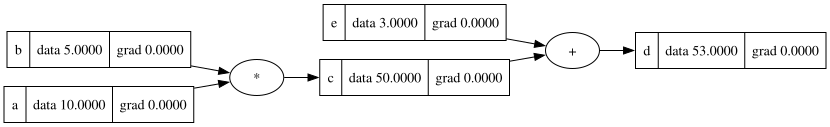

In [30]:
draw_dot(d)

### Sigmoid

Squash in range of 0  -  1

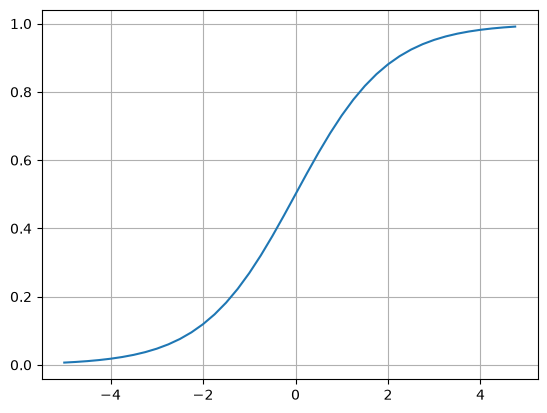

In [35]:

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

plt.plot(np.arange(-5.0, 5.0, 0.25), sigmoid(np.arange(-5.0, 5.0, 0.25))); plt.grid()

### TanH

Squash in range of -1  -  1

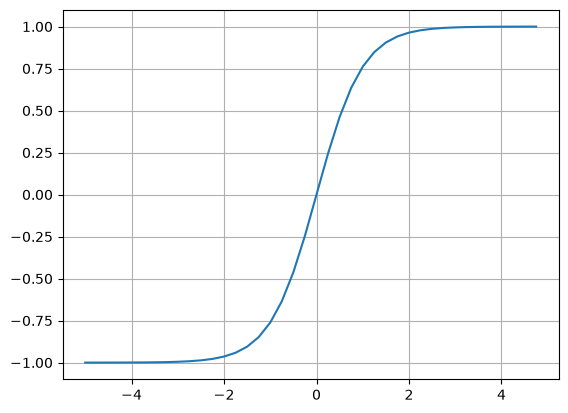

In [36]:
plt.plot(np.arange(-5.0, 5.0, 0.25), np.tanh(np.arange(-5.0, 5.0, 0.25))); plt.grid()

In [93]:
# Input Variables
x1 = Node(0.5, label = "x1")
x2 = Node(1.0, label = "x2")

# Weights
w1 = Node(0.4, label = "w1")
w2 = Node(-0.2, label = "w2")

# Bais
b = Node(0.1, label="b")

# Forward Pass
w1x1 = w1 * x1; w1x1.label = "w1x1"
w2x2 = w2 * x2; w2x2.label = "w2x2"

w1x1w2x2 = w1x1 + w2x2; w1x1w2x2.label = "w1x1w2x2"

n = w1x1w2x2 + b; n.label = "n"
o = n.sigmoid(); o.label = "o"
o.backward()

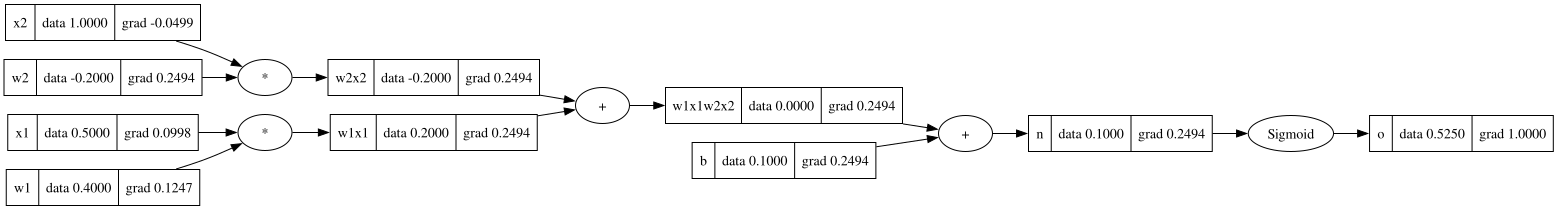

In [94]:
draw_dot(o)

In [107]:
# Using manual Sigmoid function

# Input Variables
x1 = Node(0.5, label = "x1")
x2 = Node(1.0, label = "x2")

# Weights
w1 = Node(0.4, label = "w1")
w2 = Node(-0.2, label = "w2")

# Bais
b = Node(0.1, label="b")

# Forward Pass
w1x1 = w1 * x1; w1x1.label = "w1x1"
w2x2 = w2 * x2; w2x2.label = "w2x2"

w1x1w2x2 = w1x1 + w2x2; w1x1w2x2.label = "w1x1w2x2"

n = w1x1w2x2 + b; n.label = "n"

s = n.exp() / (1 + n.exp())
o = s; o.label = "o"
o.backward()

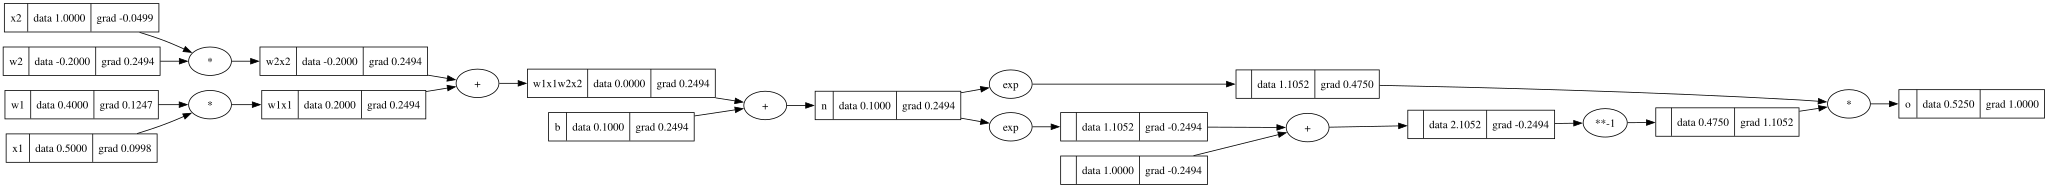

In [108]:
draw_dot(o)

### Using Pytorch

In [112]:
import torch

In [116]:
x1 = torch.tensor([0.5], dtype=torch.float64, requires_grad=True)
x2 = torch.tensor([1.0], dtype=torch.float64, requires_grad=True)
w1 = torch.tensor([0.4], dtype=torch.float64, requires_grad=True)
w2 = torch.tensor([-0.2], dtype=torch.float64, requires_grad=True)
b = torch.tensor([0.1], dtype=torch.float64, requires_grad=True)
n = x1*w1+x2*w2+b
o = torch.sigmoid(n)
print(o.item())
o.backward()
print("------------------------")
print("x2: ", x2.grad)
print("w2: ", w2.grad)
print("x1: ", x1.grad)
print("w1: ", w1.grad)

0.52497918747894
------------------------
x2:  tensor([-0.0499], dtype=torch.float64)
w2:  tensor([0.2494], dtype=torch.float64)
x1:  tensor([0.0998], dtype=torch.float64)
w1:  tensor([0.1247], dtype=torch.float64)


In [117]:
import random

In [225]:
class Neuron:

    def __init__(self, nin):
        self.w = [Node(random.uniform(-1, 1)) for _ in range(nin)]
        self.b = Node(random.uniform(-1, 1))

    def __call__(self, x):
        act = sum((wi * xi for wi, xi in zip(self.w, x)), self.b)
        out = act.tanh()
        return out

    def parameters(self):
        return self.w + [self.b]

class Layer:

    def __init__(self, nin, nout):
        self.neurons = [Neuron(nin) for _ in range(nout)]

    def __call__(self, x):
        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs) == 1 else outs

    def parameters(self):
        return [p for neuron in self.neurons for p in neuron.parameters()]

class MLP:
    def __init__(self, nin, nouts):
        sz = [nin] + nouts
        self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]

In [226]:
x = [2.0, 3.0, 1.0]

n = MLP(3, [4, 4, 1])

out = n(x)

print(out)

Node(data = -0.8907099974505891)


In [227]:
xs = [
  [2.0, 3.0, -1.0],
  [3.0, -1.0, 0.5],
  [0.5, 1.0, 1.0],
  [1.0, 1.0, -1.0],
]
ys = [1.0, -1.0, -1.0, 1.0] # desired targets

In [233]:
for k in range(200):

    ypred = [n(x) for x in xs]
    loss = sum((yout - ygt)**2 for ygt, yout in zip(ys, ypred))

    for p in n.parameters():
        p.grad = 0.0

    loss.backward() 

    for p in n.parameters():
        p.data += -0.1 * p.grad

    print(k, loss.data)

0 0.00024725105165309595
1 0.00024699324512583997
2 0.00024673596657218307
3 0.00024647921438200967
4 0.0002462229869517085
5 0.0002459672826841463
6 0.00024571209998865536
7 0.0002454574372809986
8 0.0002452032929832971
9 0.0002449496655240554
10 0.0002446965533380934
11 0.0002444439548665108
12 0.0002441918685566973
13 0.00024394029286223834
14 0.00024368922624295252
15 0.00024343866716479445
16 0.00024318861409987943
17 0.00024293906552641197
18 0.0002426900199286855
19 0.00024244147579702768
20 0.00024219343162779156
21 0.0002419458859233107
22 0.00024169883719187698
23 0.00024145228394770356
24 0.0002412062247109153
25 0.00024096065800748506
26 0.000240715582369232
27 0.00024047099633379103
28 0.0002402268984445833
29 0.00023998328725076214
30 0.00023974016130723014
31 0.00023949751917456204
32 0.00023925535941902738
33 0.0002390136806125068
34 0.00023877248133252586
35 0.0002385317601621732
36 0.00023829151569010066
37 0.00023805174651049722
38 0.00023781245122305434
39 0.0002375

In [ ]:
n([3.0, -1.0, 0.5])

Node(data = -0.9941225895483679)